In [1]:
%pip install -q jax jaxlib matplotlib ipympl


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
%matplotlib widget

## 1. Import the solver

In [ ]:
from JAX_Supersonic_Cone_Solver import (
    make_cone_grid, run_solver, plot_results
)


## 2. Grid visualization

W1021 19:10:49.098321 1136580 cuda_executor.cc:1802] GPU interconnect information not available: INTERNAL: NVML doesn't support extracting fabric info or NVLink is not used by the device.
W1021 19:10:49.103832 1135918 cuda_executor.cc:1802] GPU interconnect information not available: INTERNAL: NVML doesn't support extracting fabric info or NVLink is not used by the device.


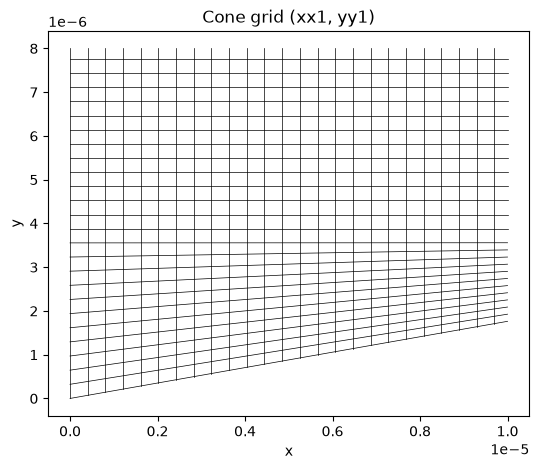

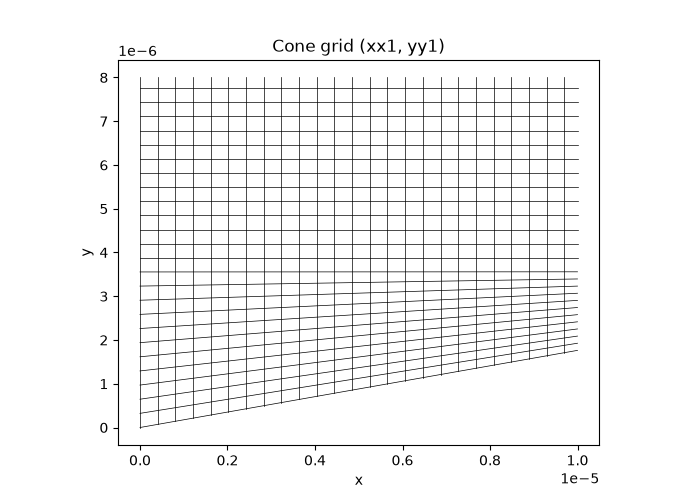

In [4]:
import matplotlib.pyplot as plt
import numpy as np

xx1, yy1, Rad, Z = make_cone_grid(nx=100, ny=100)
xx1n, yy1n = np.array(xx1), np.array(yy1)

fig, ax = plt.subplots(figsize=(7, 5))
for n in range(0, xx1n.shape[0], 4):
    ax.plot([xx1n[n, 0], xx1n[n, -1]], [yy1n[n, 0], yy1n[n, -1]], 'k-', lw=0.5)
for n in range(0, xx1n.shape[1], 4):
    ax.plot([xx1n[0, n], xx1n[-1, n]], [yy1n[0, n], yy1n[-1, n]], 'k-', lw=0.5)
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_aspect('equal')
ax.set_title('Cone grid (xx1, yy1)')
fig


## 3. Calling the solver


In [5]:
results = run_solver(
    nx=100, ny=100,
    iters=10000,
    plot_every=50,       # redraw every 50 iterations
    verbose_every=100,   # print residual every 100 iterations
    live_plot=False,
)

iter     0  residual = 4.810931e+02
iter   100  residual = 3.308100e+02
iter   200  residual = 3.078281e+02
iter   300  residual = 2.239011e+02
iter   400  residual = 1.504190e+02
iter   500  residual = 1.015945e+02
iter   600  residual = 7.931045e+01
iter   700  residual = 7.287960e+01
iter   800  residual = 7.126996e+01
iter   900  residual = 7.094546e+01
iter  1000  residual = 7.087925e+01
iter  1100  residual = 7.087121e+01
iter  1200  residual = 7.087548e+01
iter  1300  residual = 7.088082e+01
iter  1400  residual = 7.088487e+01
iter  1500  residual = 7.088755e+01
iter  1600  residual = 7.088922e+01
iter  1700  residual = 7.089023e+01
iter  1800  residual = 7.089083e+01
iter  1900  residual = 7.089119e+01
iter  2000  residual = 7.089140e+01
iter  2100  residual = 7.089152e+01
iter  2200  residual = 7.089158e+01
iter  2300  residual = 7.089162e+01
iter  2400  residual = 7.089164e+01
iter  2500  residual = 7.089165e+01
iter  2600  residual = 7.089166e+01
iter  2700  residual = 7.089

## 6. Final plots

/home/tejasbg/supersonic-JAX/JAX_cone_with_source.py:517: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(xx1, yy1, np.array(field), cmap="jet", shading="auto")
/home/tejasbg/supersonic-JAX/JAX_cone_with_source.py:537: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(xx1, yy1, np.array(results["mach"]), cmap="jet", shading="auto")


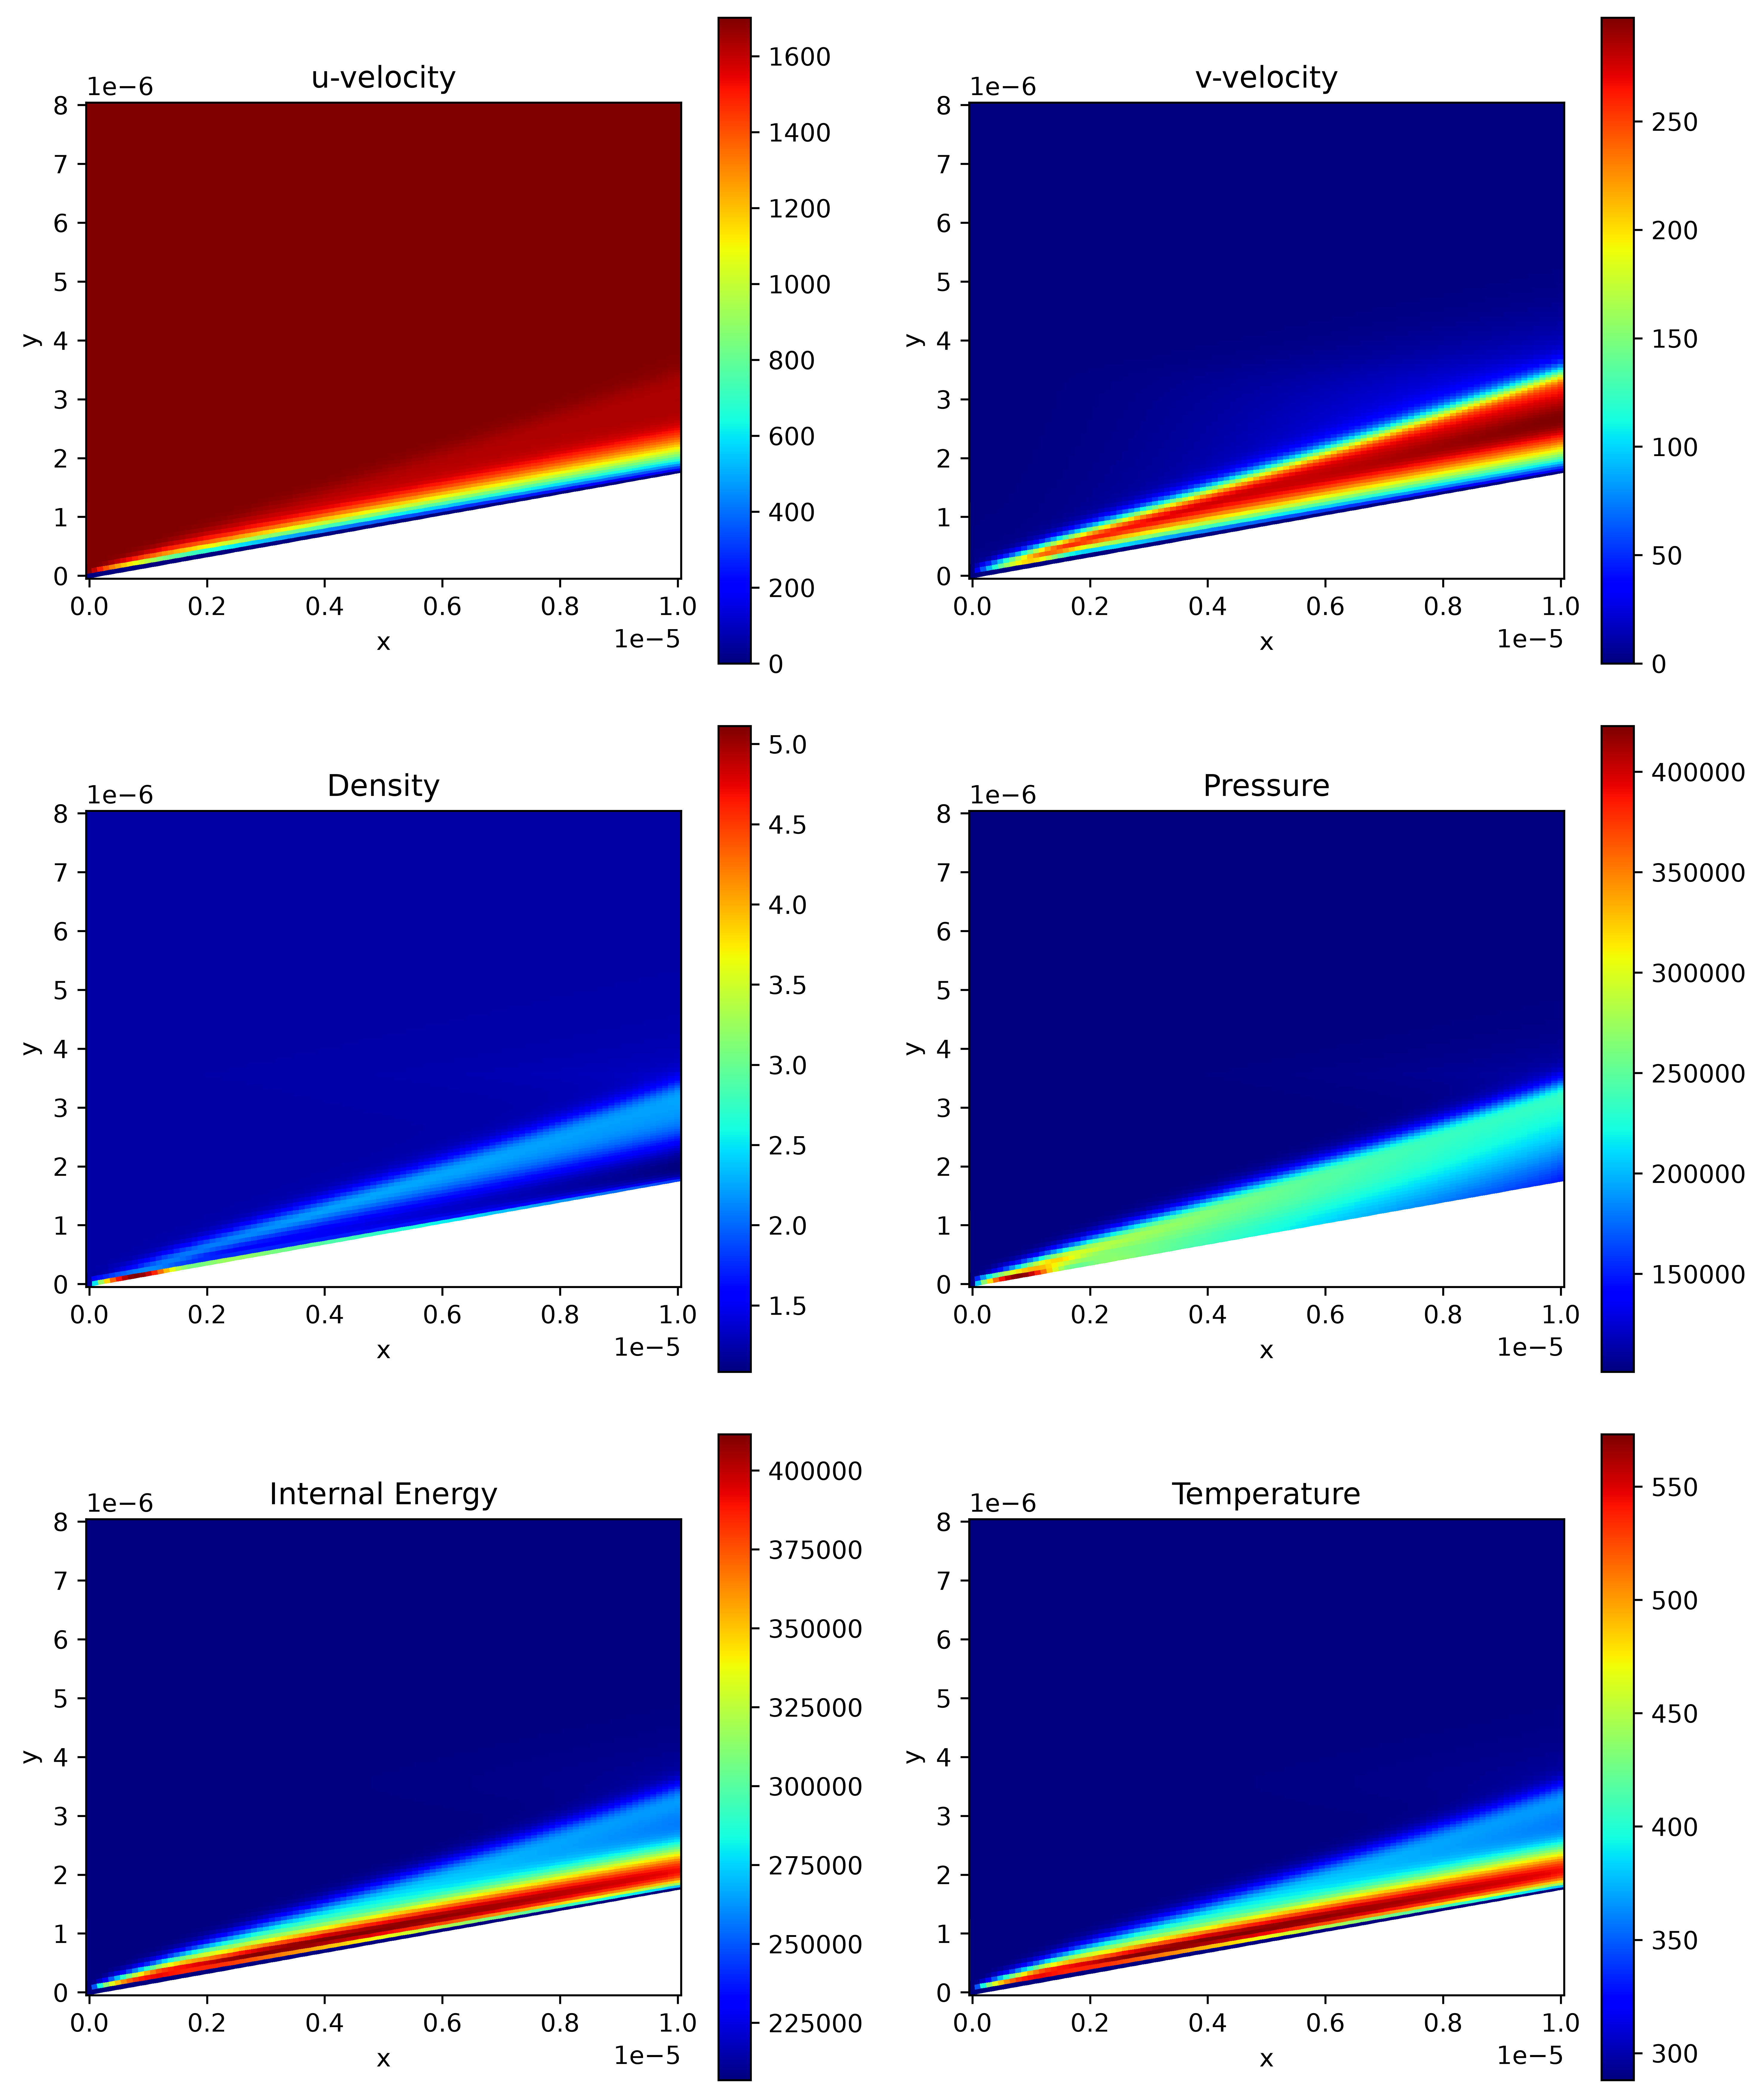

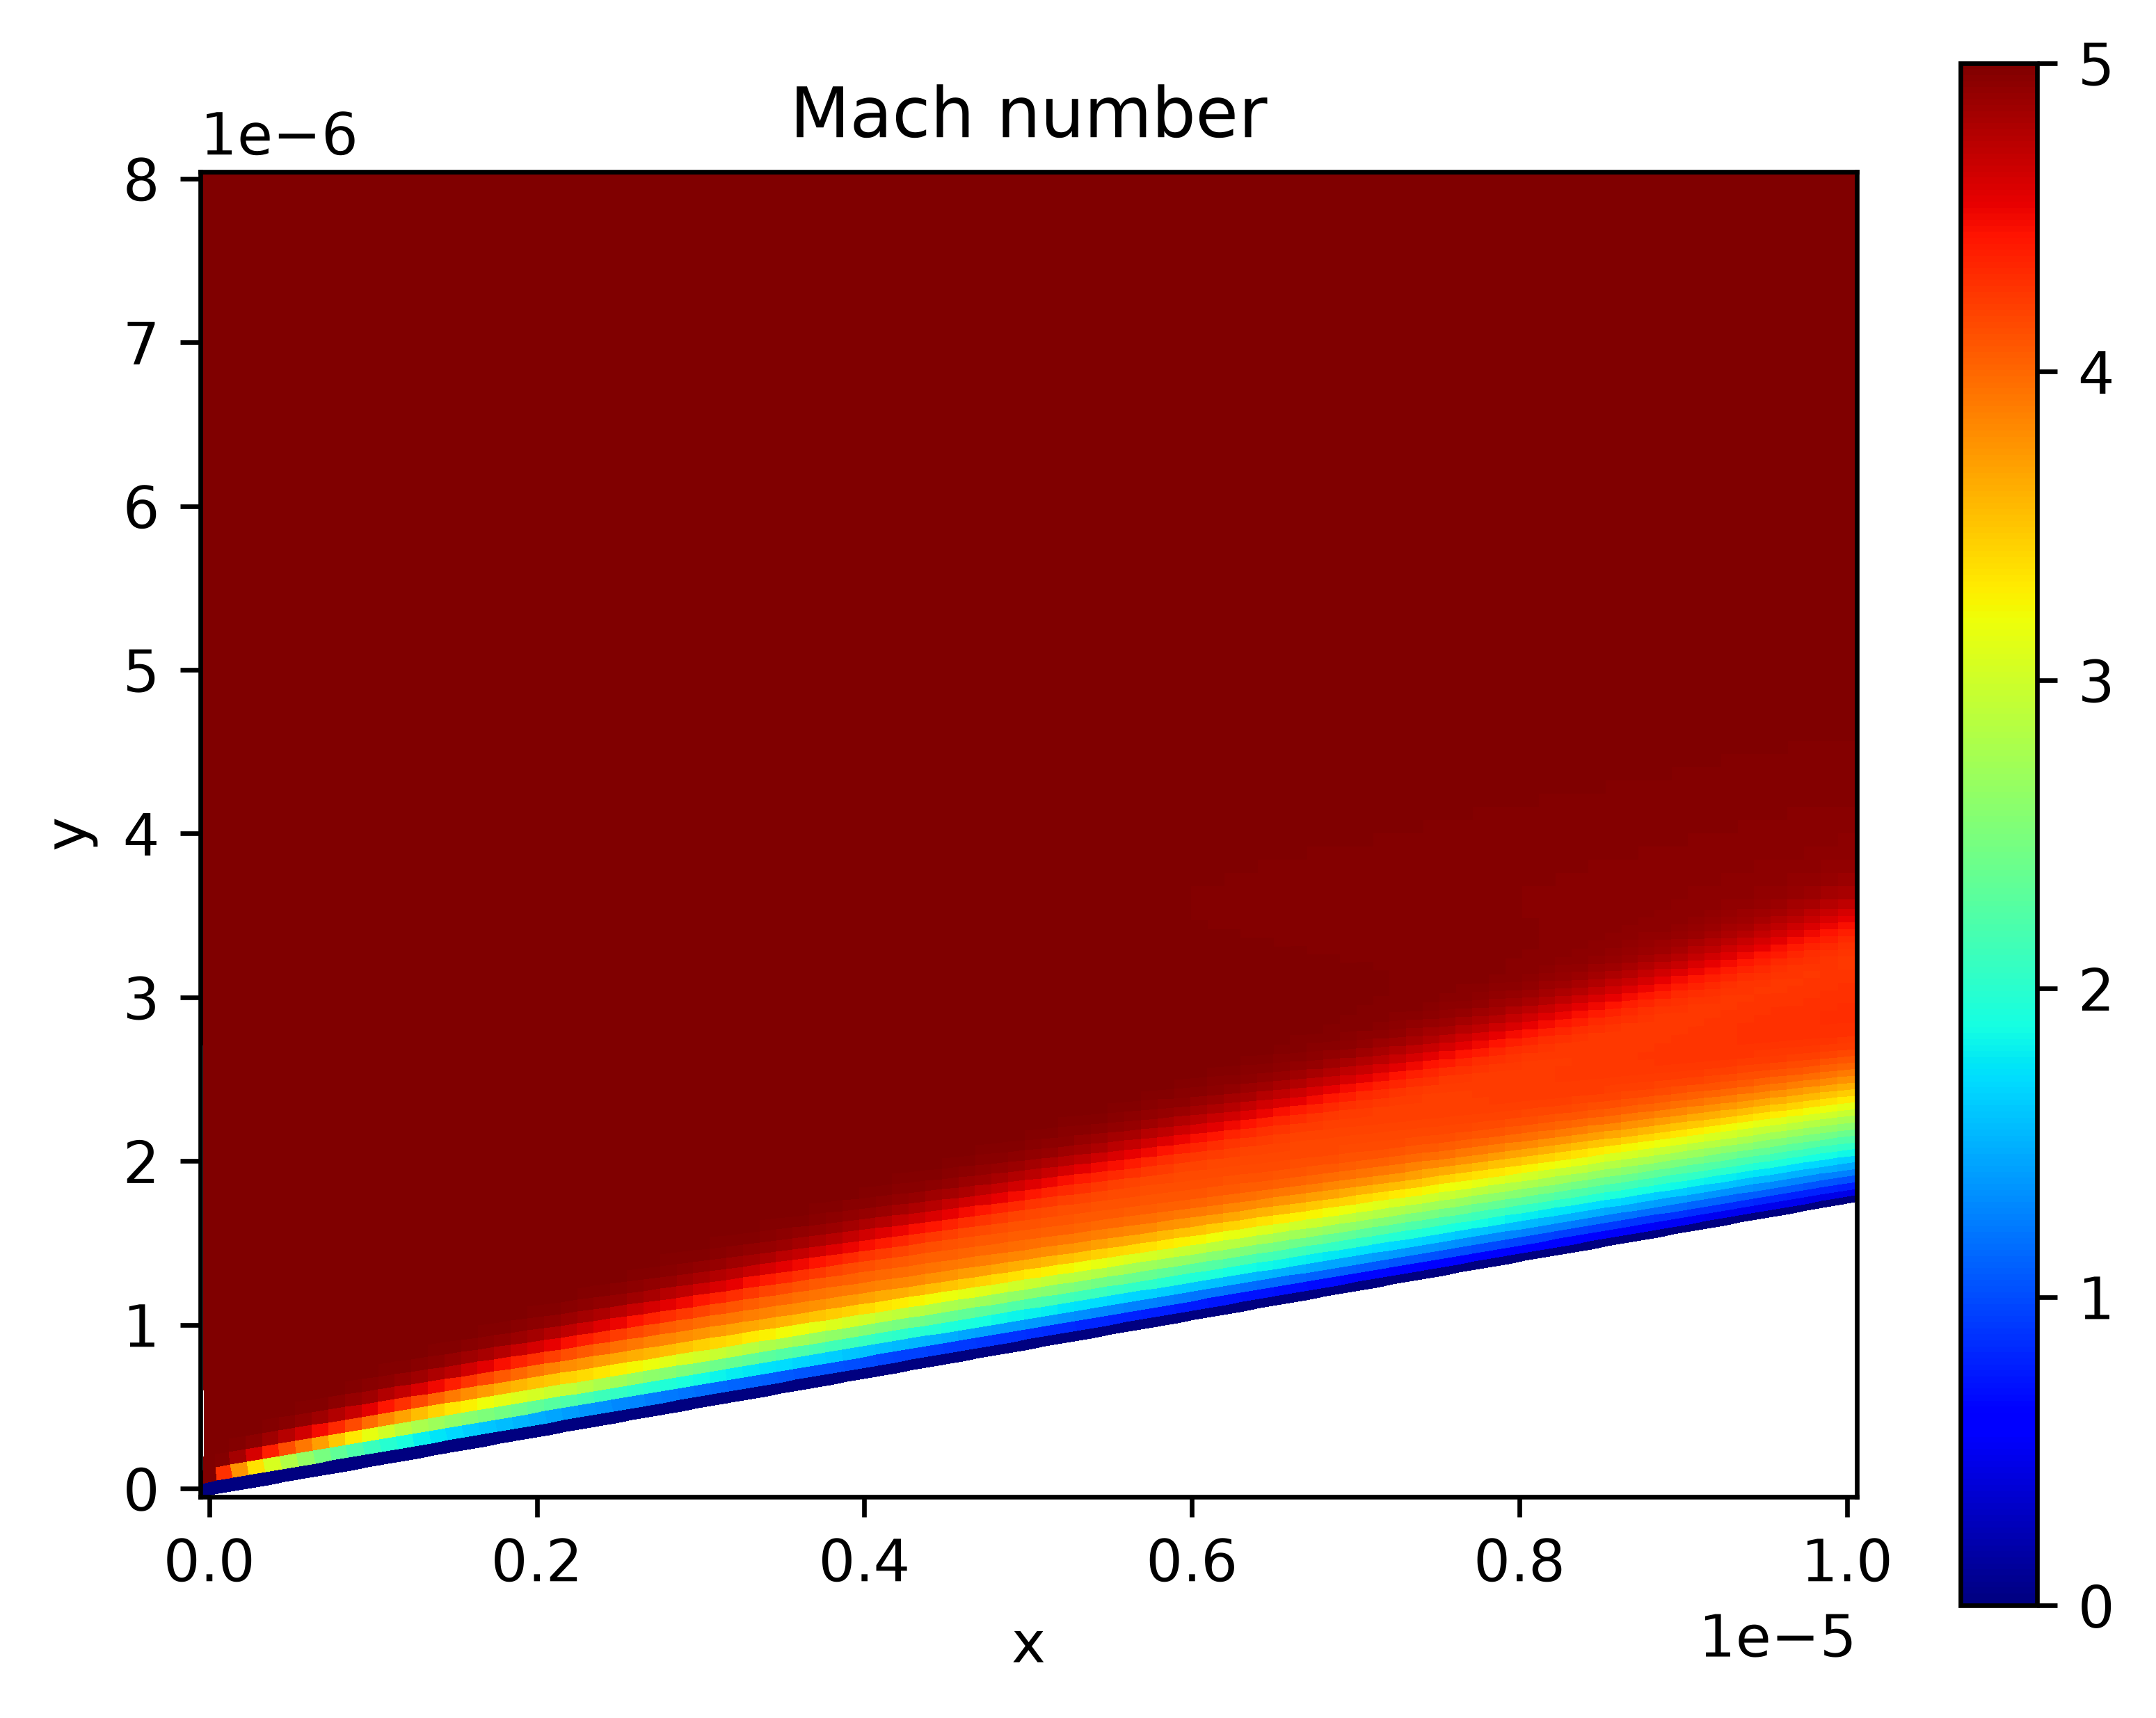

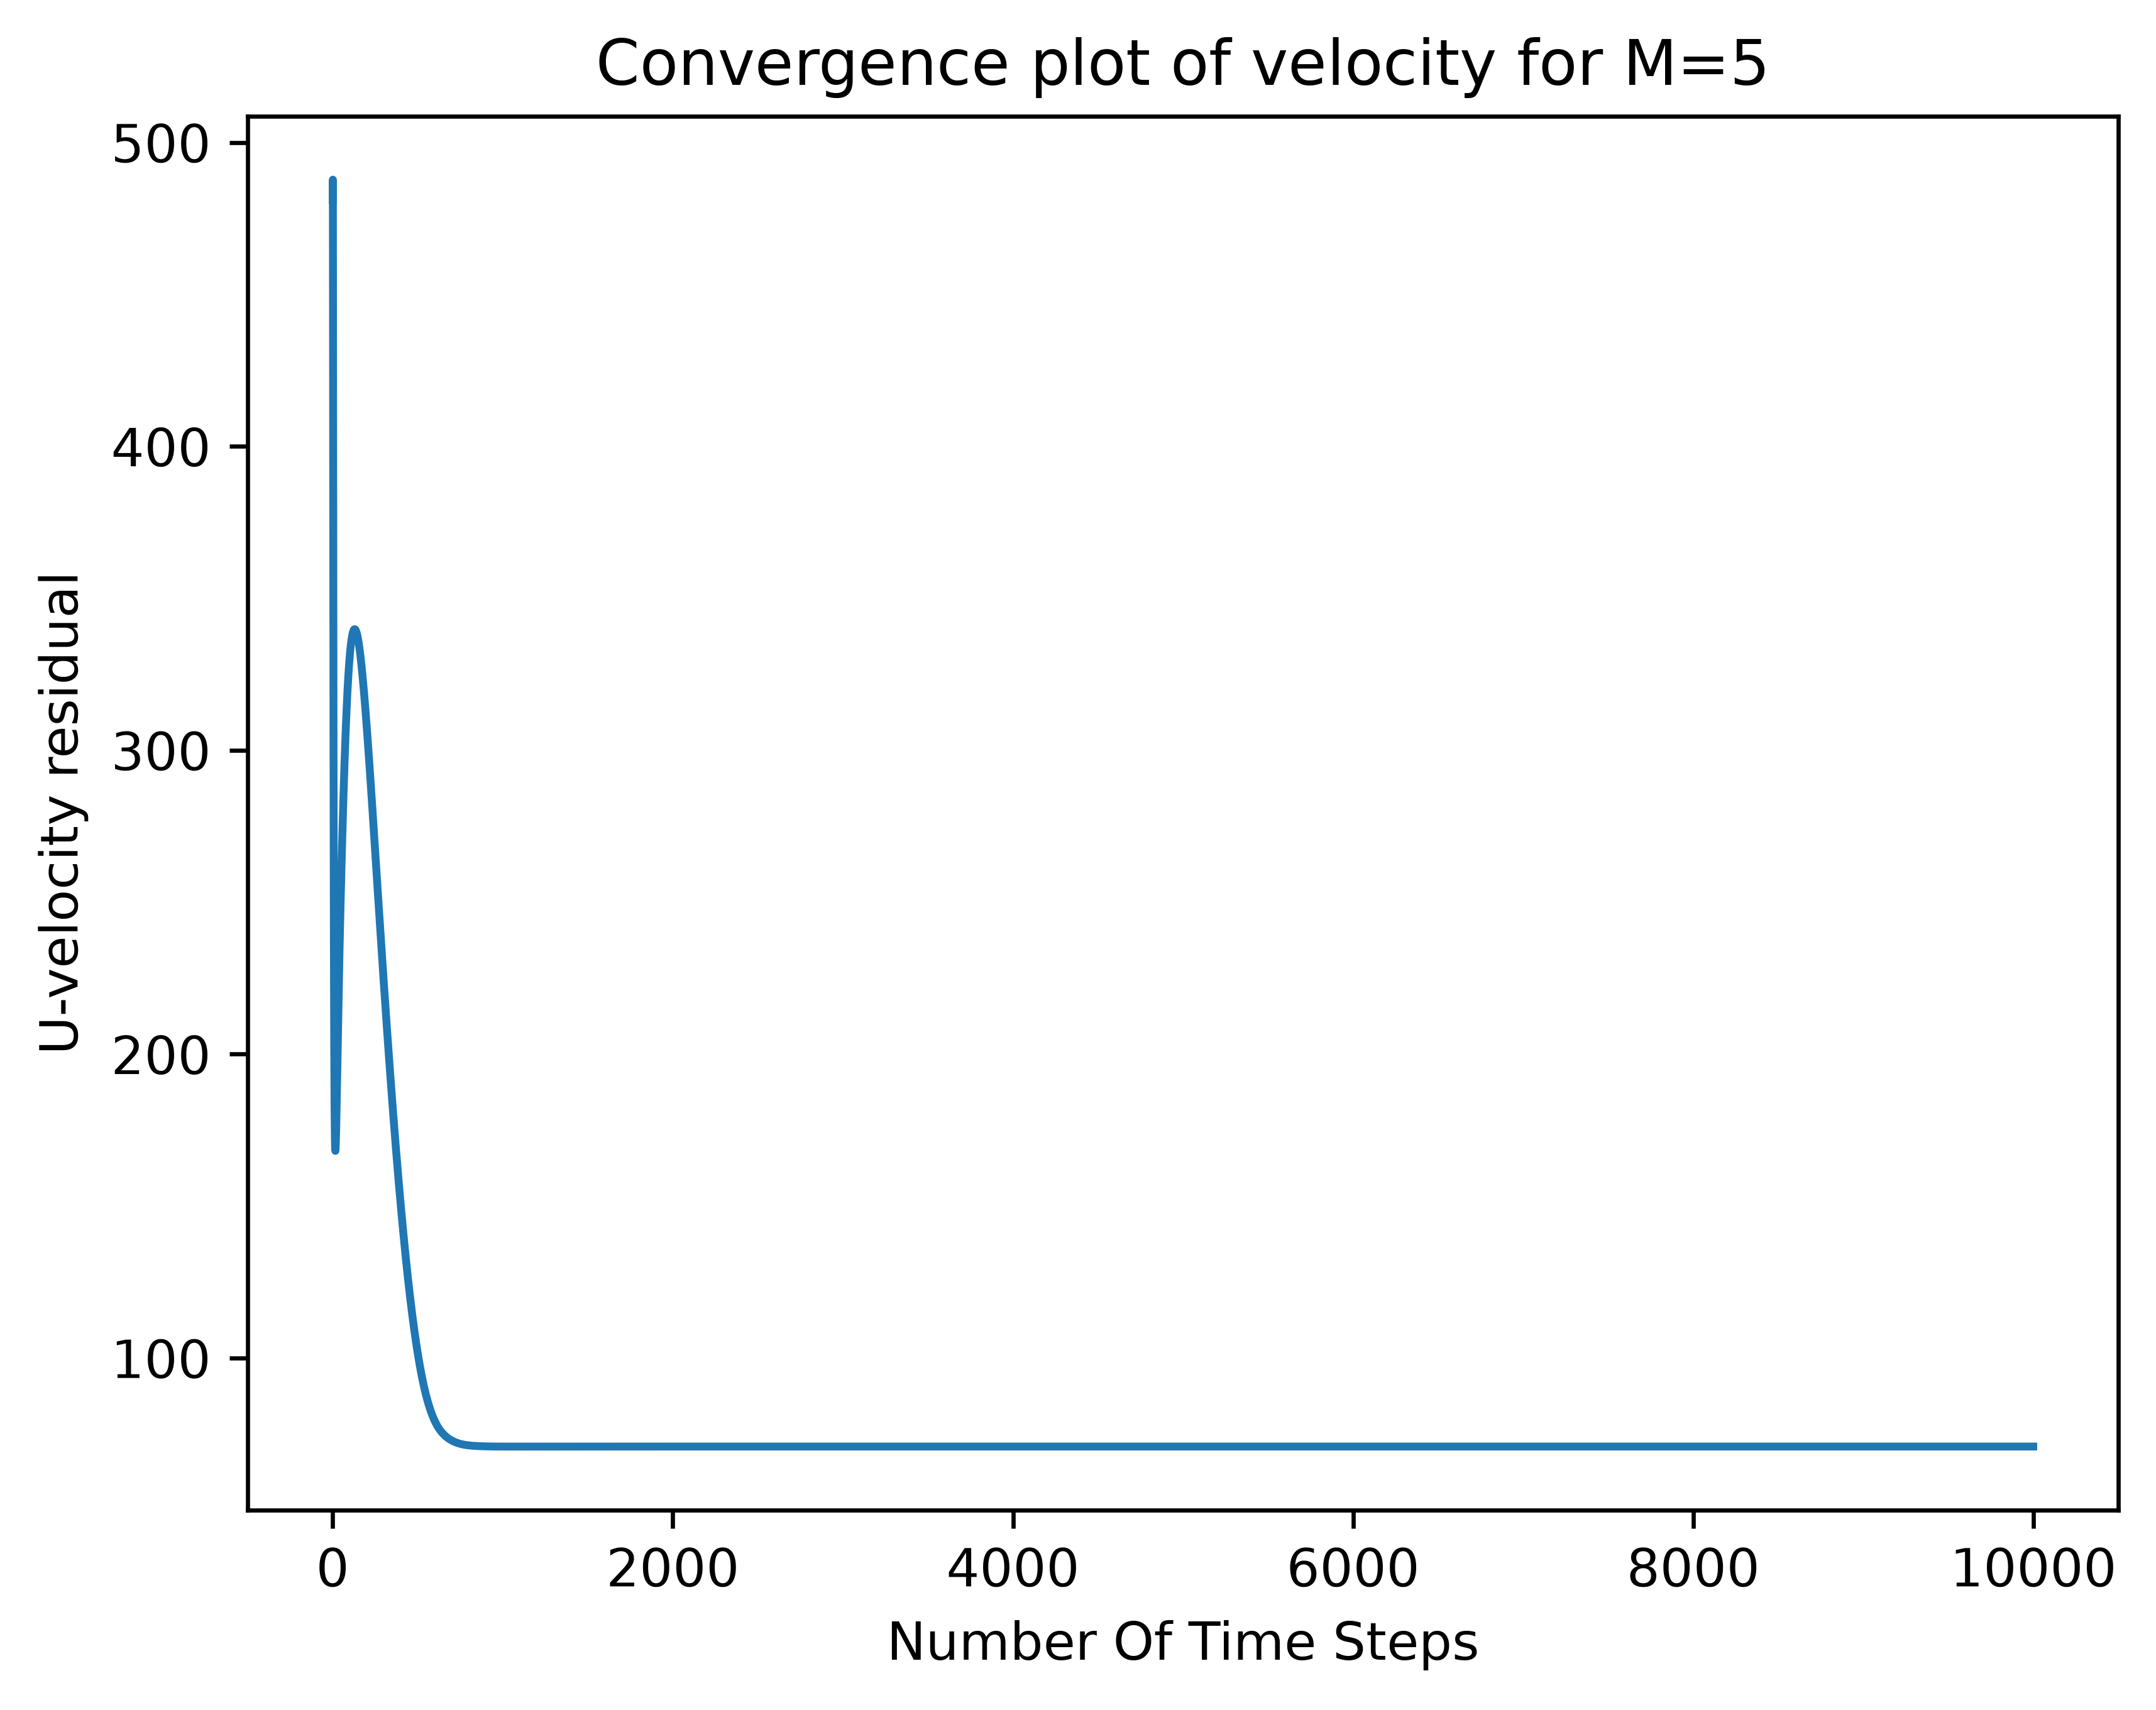

In [6]:
plot_results(results, out_dir="./outputs")

from IPython.display import Image, display
display(Image("./outputs/fields.png"))
display(Image("./outputs/mach.png"))
display(Image("./outputs/residual.png"))